In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../../../data/raw/weatherHistory.csv")
print("Shape:", df.shape)
df.head()

Shape: (96453, 12)


,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.


In [2]:
df.isnull().sum()

Formatted Date                0
Summary                       0
Precip Type                 517
Temperature (C)               0
Apparent Temperature (C)      0
Humidity                      0
Wind Speed (km/h)             0
Wind Bearing (degrees)        0
Visibility (km)               0
Loud Cover                    0
Pressure (millibars)          0
Daily Summary                 0
dtype: int64

In [3]:
duplicates = df[df.duplicated()]
duplicates.shape

(24, 12)

In [4]:
df['Precip Type'] = df['Precip Type'].ffill() #ffill(), bfill(), mode() gives same values(assign to most rain)

In [5]:
df.isnull().sum()

Formatted Date              0
Summary                     0
Precip Type                 0
Temperature (C)             0
Apparent Temperature (C)    0
Humidity                    0
Wind Speed (km/h)           0
Wind Bearing (degrees)      0
Visibility (km)             0
Loud Cover                  0
Pressure (millibars)        0
Daily Summary               0
dtype: int64

In [6]:
df['Precip Type'].value_counts()

Precip Type
rain    85741
snow    10712
Name: count, dtype: int64

In [7]:
df['Summary'].value_counts()

Summary
Partly Cloudy                          31733
Mostly Cloudy                          28094
Overcast                               16597
Clear                                  10890
Foggy                                   7148
Breezy and Overcast                      528
Breezy and Mostly Cloudy                 516
Breezy and Partly Cloudy                 386
Dry and Partly Cloudy                     86
Windy and Partly Cloudy                   67
Light Rain                                63
Breezy                                    54
Windy and Overcast                        45
Humid and Mostly Cloudy                   40
Drizzle                                   39
Breezy and Foggy                          35
Windy and Mostly Cloudy                   35
Dry                                       34
Humid and Partly Cloudy                   17
Dry and Mostly Cloudy                     14
Rain                                      10
Windy                                      8
Hu

In [8]:
df['Suitability'] = (df['Summary'] == 'Clear').astype(int)

In [9]:
df = df.drop_duplicates()

In [10]:
df = pd.get_dummies(
    df,
    columns=['Precip Type'],
    prefix='Precip',
    dtype=int
)

Handle Loud Cover

In [11]:
df['Loud Cover'].value_counts()

Loud Cover
0.0    96429
Name: count, dtype: int64

In [12]:
# Time features: weather is strongly seasonal and has a daily cycle.
# They must be extracted BEFORE 'Formatted Date' is dropped.
dt = pd.to_datetime(df['Formatted Date'].str[:19])
df['Month'] = dt.dt.month
df['Hour'] = dt.dt.hour

df = df.drop(columns=['Formatted Date', 'Summary', 'Daily Summary', 'Loud Cover'])


In [13]:
df.head()

,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Suitability,Precip_rain,Precip_snow,Month,Hour
0,9.472222,7.388889,0.89,14.1197,251.0,15.8263,1015.13,0,1,0,4,0
1,9.355556,7.227778,0.86,14.2646,259.0,15.8263,1015.63,0,1,0,4,1
2,9.377778,9.377778,0.89,3.9284,204.0,14.9569,1015.94,0,1,0,4,2
3,8.288889,5.944444,0.83,14.1036,269.0,15.8263,1016.41,0,1,0,4,3
4,8.755556,6.977778,0.83,11.0446,259.0,15.8263,1016.51,0,1,0,4,4


In [14]:
df = df.rename(columns={
    'Temperature (C)': 'Temperature',
    'Apparent Temperature (C)': 'Apparent_Temperature',
    'Wind Speed (km/h)': 'Wind_Speed',
    'Wind Bearing (degrees)': 'Wind_Bearing',
    'Visibility (km)': 'Visibility',
    'Pressure (millibars)': 'Pressure',
    'Precip_rain': 'Precip_Rain',
    'Precip_snow': 'Precip_Snow'
})

Fix bad pressure readings and add a temperature-gap feature

In [15]:
# Pressure == 0 is a sensor error, not a real reading: flag it, then impute with the median
df['Pressure_Missing'] = (df['Pressure'] == 0).astype(int)
df['Pressure'] = df['Pressure'].replace(0, np.nan)
df['Pressure'] = df['Pressure'].fillna(df['Pressure'].median())

# Gap between real and "feels like" temperature (wind chill / humidity effect)
df['Temp_Gap'] = df['Temperature'] - df['Apparent_Temperature']


Scaling the Dataset

In [16]:
from sklearn.preprocessing import StandardScaler

num_cols = ['Temperature', 'Apparent_Temperature', 'Humidity', 'Wind_Speed', 'Wind_Bearing', 'Visibility', 'Pressure']
scaler = StandardScaler()
scaler.fit(df[num_cols])

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [17]:
df.head()

,Temperature,Apparent_Temperature,Humidity,Wind_Speed,Wind_Bearing,Visibility,Pressure,Suitability,Precip_Rain,Precip_Snow,Month,Hour,Pressure_Missing,Temp_Gap
0,9.472222,7.388889,0.89,14.1197,251.0,15.8263,1015.13,0,1,0,4,0,0,2.083333
1,9.355556,7.227778,0.86,14.2646,259.0,15.8263,1015.63,0,1,0,4,1,0,2.127778
2,9.377778,9.377778,0.89,3.9284,204.0,14.9569,1015.94,0,1,0,4,2,0,0.000000
3,8.288889,5.944444,0.83,14.1036,269.0,15.8263,1016.41,0,1,0,4,3,0,2.344444
4,8.755556,6.977778,0.83,11.0446,259.0,15.8263,1016.51,0,1,0,4,4,0,1.777778


In [18]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [19]:
X = df.drop(columns=['Suitability'])
y = df['Suitability']

pd_X = pd.DataFrame(X)
pd_y = pd.Series(y)

pd_X.head()

,Temperature,Apparent_Temperature,Humidity,Wind_Speed,Wind_Bearing,Visibility,Pressure,Precip_Rain,Precip_Snow,Month,Hour,Pressure_Missing,Temp_Gap
0,9.472222,7.388889,0.89,14.1197,251.0,15.8263,1015.13,1,0,4,0,0,2.083333
1,9.355556,7.227778,0.86,14.2646,259.0,15.8263,1015.63,1,0,4,1,0,2.127778
2,9.377778,9.377778,0.89,3.9284,204.0,14.9569,1015.94,1,0,4,2,0,0.000000
3,8.288889,5.944444,0.83,14.1036,269.0,15.8263,1016.41,1,0,4,3,0,2.344444
4,8.755556,6.977778,0.83,11.0446,259.0,15.8263,1016.51,1,0,4,4,0,1.777778


In [20]:
pd_y.head()

0    0
1    0
2    0
3    0
4    0
Name: Suitability, dtype: int64

In [21]:
# stratify keeps the same share of "Clear" days (~11%) in train and test
X_train, X_test, y_train, y_test = train_test_split(
    pd_X, pd_y, test_size=0.2, random_state=42, stratify=pd_y
)
print(f"Training Samples: {len(X_train)}, Testing Samples: {len(X_test)}")


Training Samples: 77143, Testing Samples: 19286


In [22]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, precision_recall_curve

ACC_TARGET = 0.70   # accuracy must be above 70%
F1_TARGET = 0.45    # F1-score (Clear class) must be above 45%

# Hold out part of the TRAIN set to choose the decision threshold (test set stays untouched)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

# Create model (deeper trees + subsampling than the default setup)
gb_model = GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=5,
    subsample=0.8,
    random_state=42
)
gb_model.fit(X_fit, y_fit)

# Only ~11% of days are "Clear", so the default 0.5 cut-off almost never predicts "Clear"
# (recall ~9%). Pick the threshold that maximises F1 on the validation set, while keeping
# accuracy above its target.
val_proba = gb_model.predict_proba(X_val)[:, 1]
best_thr, best_f1 = 0.5, -1
for thr in np.arange(0.05, 0.95, 0.01):
    pred = (val_proba >= thr).astype(int)
    if accuracy_score(y_val, pred) > ACC_TARGET and f1_score(y_val, pred) > best_f1:
        best_thr, best_f1 = thr, f1_score(y_val, pred)
print(f"Chosen decision threshold: {best_thr:.2f}  (validation F1 = {best_f1:.3f})")

# Predict on the untouched test set
y_proba_gb = gb_model.predict_proba(X_test)[:, 1]
y_pred_gb = (y_proba_gb >= best_thr).astype(int)

# Evaluation
acc = accuracy_score(y_test, y_pred_gb)
f1 = f1_score(y_test, y_pred_gb)

print("=" * 50)
print("GRADIENT BOOSTING (tuned threshold)")
print("=" * 50)
print(f"\nAccuracy : {acc:.2%}   (target > {ACC_TARGET:.0%})  {'PASS' if acc > ACC_TARGET else 'FAIL'}")
print(f"F1 (Clear): {f1:.2%}   (target > {F1_TARGET:.0%})  {'PASS' if f1 > F1_TARGET else 'FAIL'}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb, target_names=["Not Clear", "Clear"]))


Chosen decision threshold: 0.22  (validation F1 = 0.498)
GRADIENT BOOSTING (tuned threshold)

Accuracy : 86.53%   (target > 70%)  PASS
F1 (Clear): 49.74%   (target > 45%)  PASS

Classification Report:
              precision    recall  f1-score   support

   Not Clear       0.95      0.90      0.92     17111
       Clear       0.43      0.59      0.50      2175

    accuracy                           0.87     19286
   macro avg       0.69      0.75      0.71     19286
weighted avg       0.89      0.87      0.87     19286



## Improved Confusion Matrix
Counts (with each cell's share of the test set) next to a row-normalised view that shows how well each class is recovered despite the class imbalance. The title shows whether the accuracy / F1 targets are met.

**TN** = correctly predicted *Not Clear* · **FP** = predicted *Clear* but wasn't · **FN** = missed a *Clear* day · **TP** = correctly predicted *Clear*

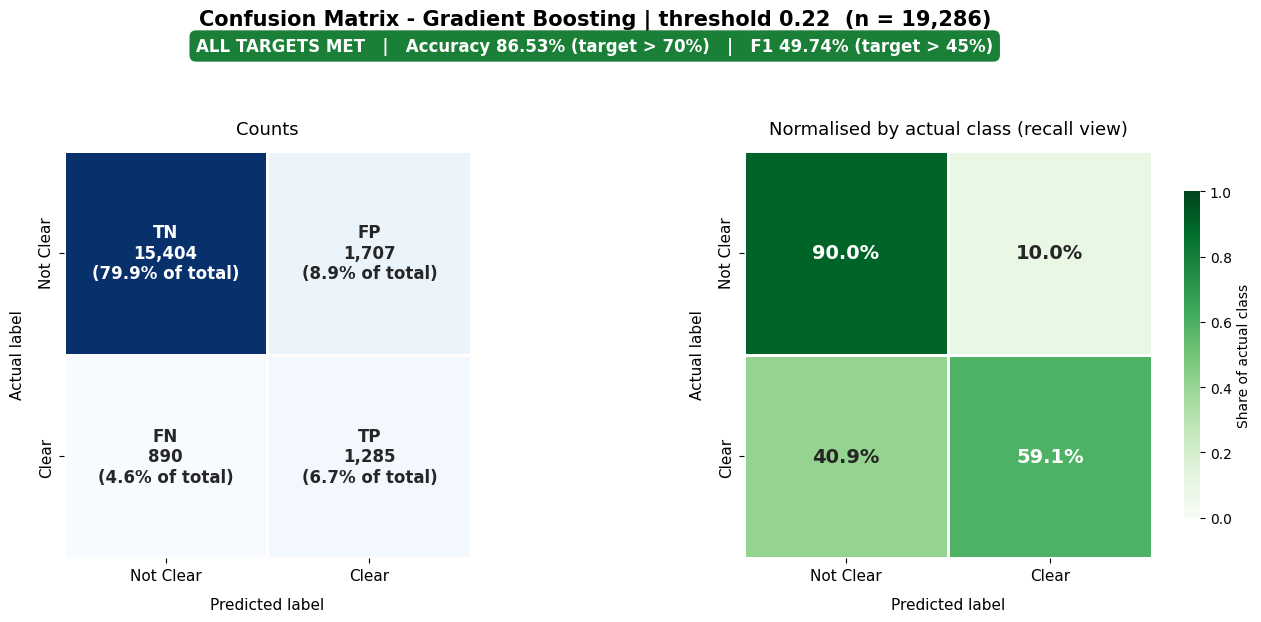

In [23]:
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score)

def plot_confusion_matrix(y_true, y_pred, class_names=("Not Clear", "Clear"),
                          title="Gradient Boosting", threshold=None,
                          acc_target=0.70, f1_target=0.45):
    """Counts + row-normalised confusion matrices, with a pass/fail check on the targets."""
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    total = cm.sum()
    tn, fp, fn, tp = cm.ravel()
    acc = (tn + tp) / total
    f1 = f1_score(y_true, y_pred)
    ok = acc > acc_target and f1 > f1_target

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Left: counts + share of all test samples
    labels = np.array([
        [f"TN\n{tn:,}\n({tn/total:.1%} of total)", f"FP\n{fp:,}\n({fp/total:.1%} of total)"],
        [f"FN\n{fn:,}\n({fn/total:.1%} of total)", f"TP\n{tp:,}\n({tp/total:.1%} of total)"],
    ])
    sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False, square=True,
                linewidths=2, linecolor="white", annot_kws={"size": 12, "weight": "bold"},
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title("Counts", fontsize=13, pad=12)

    # Right: normalised by actual class (recall view)
    labels_pct = np.array([[f"{v:.1%}" for v in row] for row in cm_pct])
    sns.heatmap(cm_pct, annot=labels_pct, fmt="", cmap="Greens", vmin=0, vmax=1,
                cbar_kws={"label": "Share of actual class", "shrink": 0.8}, square=True,
                linewidths=2, linecolor="white", annot_kws={"size": 14, "weight": "bold"},
                xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title("Normalised by actual class (recall view)", fontsize=13, pad=12)

    for ax in axes:
        ax.set_xlabel("Predicted label", fontsize=11, labelpad=10)
        ax.set_ylabel("Actual label", fontsize=11, labelpad=10)
        ax.tick_params(axis="both", labelsize=11)

    thr_txt = f" | threshold {threshold:.2f}" if threshold is not None else ""
    fig.suptitle(f"Confusion Matrix - {title}{thr_txt}  (n = {total:,})",
                 fontsize=15, fontweight="bold", y=1.03)

    # Target banner under the title
    colour = "#1a7f37" if ok else "#c62828"
    status = "ALL TARGETS MET" if ok else "TARGET MISSED"
    fig.text(0.5, 0.96,
             f"{status}   |   Accuracy {acc:.2%} (target > {acc_target:.0%})   |   "
             f"F1 {f1:.2%} (target > {f1_target:.0%})",
             ha="center", fontsize=12, fontweight="bold", color="white",
             bbox=dict(boxstyle="round,pad=0.4", facecolor=colour, edgecolor="none"))
    plt.tight_layout(rect=(0, 0, 1, 0.93))
    plt.show()
    return cm

cm = plot_confusion_matrix(y_test, y_pred_gb, threshold=best_thr,
                           acc_target=ACC_TARGET, f1_target=F1_TARGET)


### Metrics and target check

In [24]:
tn, fp, fn, tp = cm.ravel()

rows = [
    ("Accuracy",                     (tp + tn) / cm.sum(),             ACC_TARGET),
    ("F1-score (Clear)",             f1_score(y_test, y_pred_gb),      F1_TARGET),
    ("Precision (Clear)",            precision_score(y_test, y_pred_gb), None),
    ("Recall / Sensitivity (Clear)", recall_score(y_test, y_pred_gb),  None),
    ("Specificity (Not Clear)",      tn / (tn + fp),                   None),
    ("False Positive Rate",          fp / (fp + tn),                   None),
    ("False Negative Rate",          fn / (fn + tp),                   None),
]
summary = pd.DataFrame({
    "Metric": [r[0] for r in rows],
    "Value":  [f"{r[1]:.2%}" for r in rows],
    "Target": [f"> {r[2]:.0%}" if r[2] else "-" for r in rows],
    "Status": [("PASS" if r[1] > r[2] else "FAIL") if r[2] else "-" for r in rows],
})
summary.set_index("Metric")


,Value,Target,Status
Metric,,,
Accuracy,86.53%,> 70%,PASS
F1-score (Clear),49.74%,> 45%,PASS
Precision (Clear),42.95%,-,-
Recall / Sensitivity (Clear),59.08%,-,-
Specificity (Not Clear),90.02%,-,-
False Positive Rate,9.98%,-,-
False Negative Rate,40.92%,-,-


## SMOTE vs No SMOTE Comparison
Only ~11% of days are "Clear". SMOTE creates synthetic "Clear" rows in the **training data only** so the classes are balanced. Each setup is evaluated on the same untouched test set, both at the default 0.5 threshold and at a threshold tuned on the validation set.

In [25]:
# pip install imbalanced-learn   (run once if the import below fails)
from imblearn.over_sampling import SMOTENC
from sklearn.metrics import precision_score, recall_score

def tune_threshold(y_val, proba_val, acc_target=ACC_TARGET):
    """Threshold with the best validation F1 while accuracy stays above the target."""
    best_thr, best_f1 = 0.5, -1
    for thr in np.arange(0.05, 0.95, 0.01):
        p = (proba_val >= thr).astype(int)
        if accuracy_score(y_val, p) > acc_target and f1_score(y_val, p) > best_f1:
            best_thr, best_f1 = thr, f1_score(y_val, p)
    return best_thr

def make_model():
    return GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, max_depth=5,
                                      subsample=0.8, random_state=42)

# SMOTE is applied ONLY to the training part (X_fit). Validation and test stay untouched/real.
# SMOTENC is SMOTE for mixed data: the 0/1 columns are treated as categories, not interpolated.
binary_cols = [c for c in X_fit.columns if c.startswith("Precip_") or c == "Pressure_Missing"]
cat_idx = [X_fit.columns.get_loc(c) for c in binary_cols]
smote = SMOTENC(categorical_features=cat_idx, random_state=42)
X_fit_sm, y_fit_sm = smote.fit_resample(X_fit, y_fit)

print("Training class counts (Not Clear / Clear)")
print(f"  Without SMOTE: {np.bincount(y_fit)}")
print(f"  With SMOTE   : {np.bincount(y_fit_sm)}")

models = {
    "Without SMOTE": make_model().fit(X_fit, y_fit),
    "With SMOTE":    make_model().fit(X_fit_sm, y_fit_sm),
}

rows, preds = [], {}
for name, mdl in models.items():
    proba_val = mdl.predict_proba(X_val)[:, 1]
    proba_test = mdl.predict_proba(X_test)[:, 1]
    thr_tuned = tune_threshold(y_val, proba_val)
    for label, thr in [("default 0.5", 0.5), ("tuned", thr_tuned)]:
        p = (proba_test >= thr).astype(int)
        preds[(name, label)] = p
        rows.append({
            "Setup": name, "Threshold": f"{label} ({thr:.2f})",
            "Accuracy": accuracy_score(y_test, p),
            "Precision (Clear)": precision_score(y_test, p),
            "Recall (Clear)": recall_score(y_test, p),
            "F1 (Clear)": f1_score(y_test, p),
        })

comparison = pd.DataFrame(rows)
comparison["Targets met"] = np.where(
    (comparison["Accuracy"] > ACC_TARGET) & (comparison["F1 (Clear)"] > F1_TARGET), "YES", "no")
fmt_cols = ["Accuracy", "Precision (Clear)", "Recall (Clear)", "F1 (Clear)"]
comparison.style.format({c: "{:.2%}" for c in fmt_cols}).hide(axis="index")


Training class counts (Not Clear / Clear)
  Without SMOTE: [54756  6958]
  With SMOTE   : [54756 54756]


Setup,Threshold,Accuracy,Precision (Clear),Recall (Clear),F1 (Clear),Targets met
Without SMOTE,default 0.5 (0.50),90.03%,66.62%,23.22%,34.44%,no
Without SMOTE,tuned (0.22),86.53%,42.95%,59.08%,49.74%,YES
With SMOTE,default 0.5 (0.50),86.87%,42.07%,43.63%,42.83%,no
With SMOTE,tuned (0.41),84.06%,36.55%,56.18%,44.29%,no


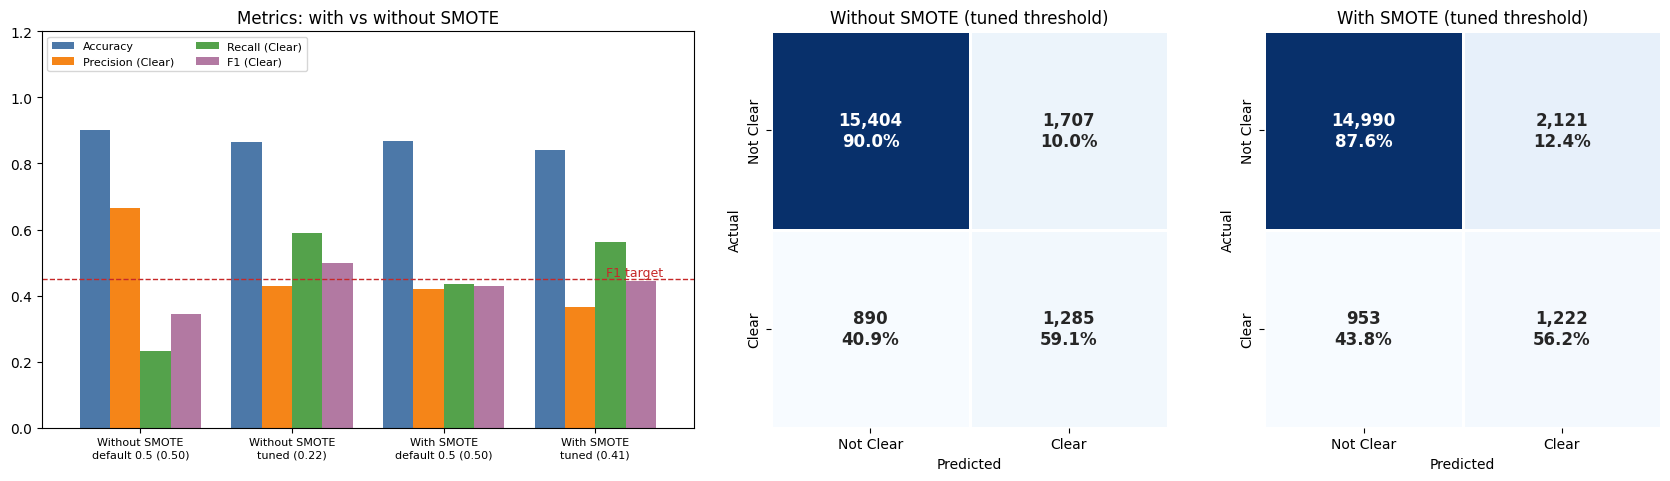

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.5, 1, 1]})

# Grouped bars: F1 / recall / precision / accuracy for all four setups
plot_df = comparison.copy()
plot_df["Label"] = plot_df["Setup"] + "\n" + plot_df["Threshold"]
plot_df.set_index("Label")[fmt_cols].plot(kind="bar", ax=axes[0], rot=0, width=0.8,
                                          color=["#4c78a8", "#f58518", "#54a24b", "#b279a2"])
axes[0].axhline(F1_TARGET, color="#c62828", ls="--", lw=1); axes[0].text(3.45, F1_TARGET + 0.01, "F1 target", color="#c62828", ha="right", fontsize=9)
axes[0].set_ylim(0, 1.2); axes[0].set_xlabel("")
axes[0].set_title("Metrics: with vs without SMOTE", fontsize=12)
axes[0].tick_params(axis="x", labelsize=8); axes[0].legend(fontsize=8, loc="upper left", ncol=2)

# Confusion matrices at the tuned threshold
for ax, name in zip(axes[1:], ["Without SMOTE", "With SMOTE"]):
    cm_ = confusion_matrix(y_test, preds[(name, "tuned")])
    pct = cm_ / cm_.sum(axis=1, keepdims=True)
    lab = np.array([[f"{cm_[i, j]:,}\n{pct[i, j]:.1%}" for j in range(2)] for i in range(2)])
    sns.heatmap(cm_, annot=lab, fmt="", cmap="Blues", cbar=False, square=True, linewidths=2,
                linecolor="white", xticklabels=["Not Clear", "Clear"],
                yticklabels=["Not Clear", "Clear"], annot_kws={"size": 12, "weight": "bold"}, ax=ax)
    ax.set_title(f"{name} (tuned threshold)", fontsize=12)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()
